# Parallelization and Sweeps

A study rarely needs a single simulation: we may want the same problem at many energies, or for many values of a parameter. This tutorial shows how to use all the cores of a computer with SAETASS, at two levels:

- **Processes for independent simulations**, with `run_sweep`.
- **Threads inside one simulation**, which SAETASS manages automatically.

The timings below depend on the machine that runs them. In both cases, the **results do not depend on the number of cores**.

## 1. Setup

Our problem is that of the fourth tutorial: a stellar wind carries the particles of a central source outwards while they diffuse. Diffusion depends on the kinetic energy of the particles, as $D \propto E^{1/3}$, so each energy is a different simulation.

`run_sweep` starts new Python processes, the **workers**, and each of them must be able to *import* the function it runs. Functions defined in a notebook cannot be imported, so we write ours to a module, `wind_sweep.py`, with the `%%writefile` command of Jupyter:

In [1]:
%%writefile wind_sweep.py
import astropy.units as u
import numpy as np

from saetass import Grid, Particle, Solver, State
from saetass import units as su


def simulate(E):
    """Distribution of the particles of kinetic energy E after 2 Myr."""
    grid = Grid.uniform(
        r_min=0.0 * u.pc,
        r_max=100.0 * u.pc,
        num_r_cells=500,
        t_min=0.0 * u.Myr,
        t_max=2.0 * u.Myr,
        num_timesteps=20000,
    )
    r = grid.r_centers
    D = 3e27 * (E / (10 * u.GeV)).to_value(u.one) ** (1 / 3) * u.cm**2 / u.s
    solver = Solver(
        state=State(
            grid, psi_p=np.zeros(grid.shape) * su.PSI_P, particle=Particle.PROTON
        ),
        problem_type="advection-diffusion-source",
        operator_params={
            "advection": {
                "v_centers": np.full(grid.num_cells_r, 50.0) * u.km / u.s,
                "limiter": "minmod",
                "order": 2,
                "cfl": 0.8,
                "inflow_value_U": 0.0 * su.AREA * su.PSI_P,
            },
            "diffusion": {"D_values": np.full(grid.num_cells_r, D.value) * D.unit},
            "source": {
                "source": np.exp(-(r**2) / (2 * (5.0 * u.pc) ** 2)) * su.SOURCE_PSI_P
            },
        },
        quiet=True,
    )
    return solver.run().psi_p.to_value(su.PSI_P).ravel()

Writing wind_sweep.py


In a script there is no need for a separate module: it is enough to define the function at the top level of the script and to put the rest of the code under `if __name__ == "__main__":`, as the [first example](../../examples/01_multi_energy_diffusion.rst) does.

## 2. Running a sweep in parallel processes

Let us simulate 16 energies between 1 GeV and 100 TeV, first one after the other and then with `run_sweep`. We only show warnings, since every simulation would otherwise log its own messages.

In [2]:
import time

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from wind_sweep import simulate

from saetass import parallel
from saetass.cli import set_log_level
from saetass.sweep import run_sweep

set_log_level("WARNING")

energies = np.logspace(0, 5, 16) * u.GeV
simulate(energies[0])  # the first run may compile the numerical kernels

start = time.perf_counter()
serial = [simulate(E) for E in energies]
t_serial = time.perf_counter() - start

start = time.perf_counter()
swept = run_sweep(simulate, energies)
t_sweep = time.perf_counter() - start

print(f"Usable physical cores: {parallel.usable_cores()}")
print(f"One after the other:   {t_serial:.1f} s")
print(f"With run_sweep:        {t_sweep:.1f} s ({t_serial / t_sweep:.1f}x faster)")
print("Same results:", np.array_equal(serial, swept))

Usable physical cores: 8
One after the other:   10.1 s
With run_sweep:        3.0 s (3.3x faster)
Same results: True


The results come in the order of the tasks and are identical to those of the serial runs. The gain is smaller than the number of cores, partly because starting the workers, which import SAETASS, takes a fixed time: the longer the simulations, the better sweeps scale. For very short simulations, a sweep can even be slower.

By default, `run_sweep` uses one worker per usable physical core. The `max_workers` argument sets another number, for instance to leave some cores free. Every worker runs its simulation with a single thread, so the workers do not compete with each other.

We can now compare the energies:

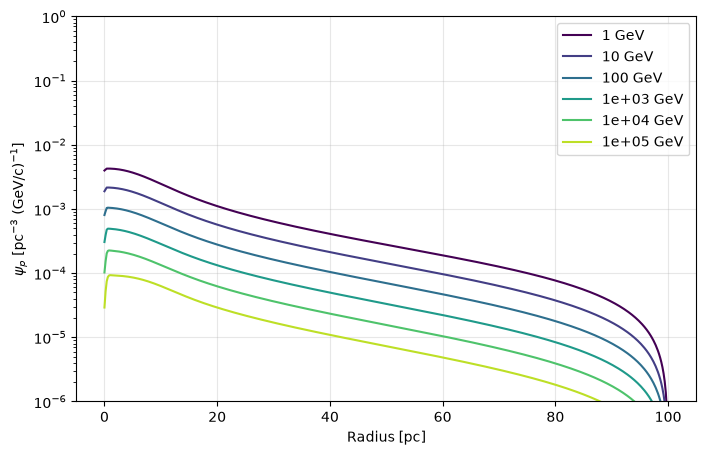

In [3]:
r = np.linspace(0.0, 100.0, 500)
colors = plt.cm.viridis(np.linspace(0.0, 0.9, len(energies)))

fig, ax = plt.subplots(figsize=(8, 5))
for E, psi, color in zip(energies[::3], swept[::3], colors[::3]):
    ax.semilogy(r, psi, color=color, label=f"{E.value:.3g} GeV")
ax.set_xlabel("Radius [pc]")
ax.set_ylabel(r"$\psi_p$ [pc$^{-3}$ (GeV/c)$^{-1}$]")
ax.set_ylim(1e-6, 1e0)
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

### Sweeping several parameters

A task can be any object that can be pickled, such as a tuple or a dictionary, so that a sweep can cover several parameters. `itertools.product` builds every combination:

```python
from itertools import product


def simulate(task):
    model, E = task
    ...


tasks = list(product(["kolmogorov", "kraichnan", "bohm"], energies))
results = run_sweep(simulate, tasks)
```

Return only what you need, since the results are copied between processes. If a simulation fails, `run_sweep` raises its exception after the rest finish.

## 3. Using threads inside one simulation

When a grid has several momenta, most operators treat each momentum (or each radius, in the case of losses) independently. SAETASS distributes these rows over **threads**, and chooses how many from the work of the simulation and the idle cores of the machine. Light simulations, and all those on 1D grids such as the one above, run serially because starting threads would cost more than it saves.

Let us consider electrons that diffuse and cool on a grid of 101 momenta and 400 radii:

In [4]:
from saetass import Grid, Particle, Solver, State
from saetass import units as su

p = np.logspace(0, 4, 101) * su.MOMENTUM
r_2d = np.linspace(0.0, 50.0, 400) * u.pc
shape = (p.size, r_2d.size)
p_column = p.value[:, np.newaxis]


def run_electrons():
    """Distribution of the electrons, and seconds taken by the simulation."""
    grid = Grid(r_centers=r_2d, p_centers=p, t_grid=np.linspace(0.0, 0.5, 201) * u.Myr)
    D = np.broadcast_to(0.5 * p_column ** (1 / 3), shape) * u.pc**2 / u.Myr
    P_dot = np.broadcast_to(-0.02 * p_column**2, shape) * su.MOMENTUM / u.Myr
    profile = np.exp(-(r_2d**2) / (2 * (2.0 * u.pc) ** 2)).value
    solver = Solver(
        state=State(grid, psi_p=np.zeros(shape) * su.PSI_P, particle=Particle.ELECTRON),
        problem_type="diffusion-loss-source",
        operator_params={
            "diffusion": {"D_values": D},
            "loss": {
                "P_dot": P_dot,
                "limiter": "minmod",
                "order": 2,
                "cfl": 0.8,
                "inflow_value_U": 0.0 * su.MOMENTUM * su.PSI_P,
            },
            "source": {"source": p_column**-2.0 * profile * su.SOURCE_PSI_P},
        },
        quiet=True,
    )
    start = time.perf_counter()
    psi = solver.run().psi_p.to_value(su.PSI_P)
    return psi.copy(), time.perf_counter() - start

`parallel.set_max_threads()` limits the threads of the kernels, and `None` goes back to the automatic choice. With it we can measure what the threads gain:

In [5]:
run_electrons()  # the first run may compile the numerical kernels

parallel.set_max_threads(1)
psi_serial, t_serial = run_electrons()
parallel.set_max_threads(None)
psi_threads, t_threads = run_electrons()

print(f"One thread:       {t_serial:.2f} s")
print(f"Automatic choice: {t_threads:.2f} s ({t_serial / t_threads:.1f}x faster)")
print("Same results:", np.array_equal(psi_serial, psi_threads))

One thread:       0.26 s
Automatic choice: 0.12 s (2.2x faster)
Same results: True


At the `DEBUG` level, the log messages tell the team of threads that SAETASS chooses. `team_size()` gives it too, for the last simulation that was created:

In [6]:
print("Threads of the last simulation:", parallel.team_size())

Threads of the last simulation: 8


## 4. Choosing between processes and threads

| Case | Use |
|---|---|
| Many independent simulations | `run_sweep`: processes scale much better than threads |
| One large simulation, with many momenta | The automatic threads, with nothing to set up |
| Simulations started by hand side by side, or a shared machine | A limit of threads for each one |

The limits can also be set in the shell, before starting Python:

- `SAETASS_MAX_THREADS` is the limit of `set_max_threads()`. It only affects SAETASS.
- `NUMBA_NUM_THREADS` sets the threads available to Numba, which bound those of SAETASS and of any other Numba code of the process.

```bash
# Two simulations on a machine of 16 cores
SAETASS_MAX_THREADS=8 python first.py &
SAETASS_MAX_THREADS=8 python second.py &
```

The threads wait actively for each other, so a simulation with more threads than idle cores can be **much slower** than a serial one. This is why a sweep should not be written by starting many simulations at once: `run_sweep` already gives one thread to each.

## Summary

In this tutorial, you learned:
1. How to run **independent simulations** in parallel with `run_sweep`, from a notebook or from a script.
2. How sweeps over **several parameters** are written.
3. How SAETASS parallelizes a **single simulation** with threads, and how to limit them.
4. How to choose between **processes** and **threads**.

The API reference has a [page about performance](../../api/performance.rst) with the details.